Importation des bibliothèques

In [140]:
from scipy.io.wavfile import read
import numpy as np
from numpy.fft import fft, fftshift, ifft, fftfreq
import matplotlib.pyplot as plt
import matplotlib
import scipy.signal as signal
import librosa
import librosa.display
import IPython.display as ipd
from sklearn import decomposition
import math

Téléchargement de l'audio

In [141]:
def chargement_audio(nom_fichier):
    rate = 5500
    son, rate = librosa.load("Fichiers_sonores/" + nom_fichier, sr = rate)
    return son, rate

Affichage du signal

In [142]:
def affichage_signal(son, rate):
       fig, ax = plt.subplots(figsize=(10, 3))
       librosa.display.waveshow(son, sr=rate, ax=ax,x_axis='time')
       ax.set(title='The sound waveform',
       xlabel='Time [s]')
       ax.legend()

Spectrogramme

In [143]:
def creation_spectrogramme(son_stft,afficher_graph=False):
    # Spectrogramme en amplitude
    son_stft_Magnitude = np.abs(son_stft)

    #Plot Spectogram
    spec = librosa.amplitude_to_db(son_stft_Magnitude, ref = np.max)
    if afficher_graph:
        librosa.display.specshow(spec,y_axis = 'hz',sr=rate,hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet)
        plt.title('Audio spectrogram')
    return son_stft_Magnitude, spec

In [144]:
def plot_spectrogram(frequencies, times, spectrogram, title="Spectrogram"):

    magnitude = np.abs(spectrogram)
    plt.figure(figsize=(10, 6))
    plt.pcolormesh(times, frequencies, 20 * np.log10(magnitude), shading='gouraud') #20 log de magnitude = pour mettre l'amplitude en dB
    plt.colorbar(label="Amplitude (dB)")
    plt.title(title)
    plt.xlabel("Temps (s)")
    plt.ylabel("Fréquence (Hz)")
    plt.show()


NMF

Initialisation

In [145]:
def init_NMF(son_stft_Magnitude):
    epsilon = 1e-10 # erreur 
    V = son_stft_Magnitude + epsilon
    return V

Fonction de la beta divergence

In [146]:
def calcul_divergence(V,W,H, divergence):
    
    """
    divergence = 2 : Norme de Frobenius (erreur quadratique)
    divergence = 1 : Divergence de Kullback-Leibler (KL) 
    divergence = 0 : Divergence Itakura-Saito (IS)
    """ 
    
    if divergence == 0 : return np.sum( V/(W@H) - np.log10(V/(W@H)) -1 )
    
    if divergence == 1 : return np.sum( V*np.log10(V/(W@H)) + (W@H - V))
    
    if divergence == 2 : return 1/2*np.linalg.norm(W@H-V)

In [147]:
def plot_NMF_iter(W, H,divergence,iteration = None):
    
    f = plt.figure(figsize=(4,4))
    f.suptitle(f"NMF Iteration {iteration}, for divergence = {divergence}", fontsize=8,)
    
    # definitions for the axes
    V_plot = plt.axes([0.35, 0.1, 1, 0.6])
    H_plot = plt.axes([0.35, 0.75, 1, 0.15])
    W_plot = plt.axes([0.1, 0.1, 0.2, 0.6])

    D = librosa.amplitude_to_db(W@H, ref = np.max)

    librosa.display.specshow(W,y_axis = 'hz', sr=rate, hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet, ax=W_plot)
    librosa.display.specshow(H,y_axis = 'hz', sr=rate, hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet, ax=H_plot)
    librosa.display.specshow(D,y_axis = 'hz', sr=rate, hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet, ax=V_plot)

    W_plot.set_title('Dictionnary W', fontsize=10)
    H_plot.set_title('Temporal activations H', fontsize=10)

    W_plot.axes.get_xaxis().set_visible(False)
    H_plot.axes.get_xaxis().set_visible(False)
    V_plot.axes.get_yaxis().set_visible(False)

Fonction NMF

In [148]:
def NMF(V,S, divergence, epsilon = 0.05, MAXITER = 5000, displayEveryNiter = None, afficher_graph=False):

    """
        divergence = 2 : Norme de Frobenius (erreur quadratique)
        divergence = 1 : Divergence de Kullback-Leibler (KL) 
        divergence = 0 : Divergence Itakura-Saito (IS)
    """
    compteur  = 0
    fonction_cout = []
    erreur = 1
    
    K, N = np.shape(V)
    
    # On initialise de manière aléatoire W0 et H0 (l=0)
    W = np.abs(np.random.normal(loc=0, scale = 2.5, size=(K,S)))    
    H = np.abs(np.random.normal(loc=0, scale = 2.5, size=(S,N)))
    
    # Affichage de la première itération
    #plot_NMF_iter(W,H,beta,compteur)


    while erreur >= epsilon and compteur <= MAXITER:
        # Mise à jour de H et W
        match divergence:
            case 2:
                H = H * (W.T @ V) / (W.T @ W @ H + 1e-9)  
                W = W * (V @ H.T) / (W @ H @ H.T + 1e-9)
            case 1: 
                H = H * (W.T @ (V / (W @ H + 1e-9))) / (W.T @ np.ones_like(V) + 1e-9)  # Ajout de 1e-9 pour éviter la division par zéro
                W = W * ((V / (W @ H + 1e-9)) @ H.T) / (np.ones_like(V) @ H.T + 1e-9)       
            case 0:
                H = H * (W.T @ (V / (W @ H + 1e-9)**2)) / (W.T @ (1 / (W @ H + 1e-9)) + 1e-9)
                W = W * ((V / (W @ H + 1e-9)**2) @ H.T) / ((1 / (W @ H + 1e-9)) @ H.T + 1e-9)

        # Calcul de la fonction de coût
        erreur = calcul_divergence(V,W,H, divergence)
        fonction_cout.append( erreur )
        
        if compteur%displayEveryNiter == 0 and afficher_graph : plot_NMF_iter(W,H,divergence,compteur)

        compteur +=1
    
    if compteur -1 == MAXITER : print(f"On est arrivés à {MAXITER} itérations.")
    else : print(f" La fonction converge au bout de {compteur-1} iterations.")
        
    return W,H, fonction_cout

Affichage de la fonction de cout

In [149]:
def affichage_cout(fonction_cout, divergence):
    plt.figure(figsize=(5,3))
    plt.plot(fonction_cout)
    plt.title("Fonction de coût")
    plt.xlabel("Nombre d'itérations")
    plt.ylabel(f"Divergence bêta pour bêta = {divergence} ")
 #On cherche à minimiser la fonction de coût, on voit clairement que le meilleur résultat  est obtenu pour beta = 2 (observation pour piano_mix)

Filtrage des sources

In [150]:
def filtrage_sources(S,W, H,V,afficher_graph=False):
    if afficher_graph:
        f, axs = plt.subplots(nrows=1, ncols=S,figsize=(20,5))
    spectrogrammes_filtre = []
    for i in range(S):
        # Filtrage de chaque source
        WsHs = np.outer(W[:,i],H[i,:])
        spectrogramme_filtre = WsHs /((W@H) * V + 1e-9)
        # Calculer le spectrogramme filtré
        D = librosa.amplitude_to_db(spectrogramme_filtre, ref = np.max)
        # Affichage du spectrogramme filtré
        if afficher_graph:
            axs[i].set_title(f"Frequency Mask of Audio Source s = {i+1}") 
            librosa.display.specshow(D,y_axis = 'hz', sr=rate,hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet, ax = axs[i])
        spectrogrammes_filtre.append(spectrogramme_filtre)
    return spectrogrammes_filtre

Reconstruction du signal

In [151]:
def reconstruction_signal(S,son_stft,spectrogrammes_filtre,FENETRE,SAUT):
    son_stft_angle = np.angle(son_stft)
    sons_reconstruits = []
    for i in range(S):
        fourier_inverse = spectrogrammes_filtre[i] * np.exp(1j*son_stft_angle)
        source_reconstruite   = librosa.istft(fourier_inverse, n_fft = FENETRE, hop_length = SAUT)
        sons_reconstruits.append(source_reconstruite)
    return sons_reconstruits

Affichage signaux reconstruits

In [152]:
def affichage_signaux(S,sons_reconstruits,rate):
    fig, ax = plt.subplots(nrows=S, ncols=1, sharex=True, figsize=(10, 8))
    for i in range(S):
        librosa.display.waveshow(sons_reconstruits[i], sr=rate, ax=ax[i],label=f'Source {i}',axis='time')
        ax[i].set(xlabel='Temps [s]')
        ax[i].legend()

Ecoute des sources séparées

In [153]:
def ecoute_signaux_separes(S,sons_reconstruits,rate):
    for i in range(S):
        ipd.display(f"Source {i}",ipd.Audio(sons_reconstruits[i], rate=rate))

Protocole complet de séparation de sources audio

In [154]:
def separation_source(fichier,S,divergence,afficher_graph=False,afficher_sons=True):
    #Chargement plus affichage audio
    son, rate = chargement_audio(fichier)
    #affichage_signal(son, rate)

    #spectrogramme avec librosa
    FENETRE = 512
    SAUT = 256
    son_stft = librosa.stft(son, n_fft = FENETRE, hop_length = SAUT)
    son_stft_Magnitude, spec  = creation_spectrogramme(son_stft,afficher_graph)

    #spectrogramme sans librosa
    #taille_fenetres = 1000
    #points_en_commun = 20
    #son_stft, t, spectrogramme = signal.stft(son, fs=rate, nperseg = taille_fenetres, noverlap = points_en_commun)
    #son_stft_Magnitude = np.abs(son_stft)
    #plot_spectrogram(son_stft, t, spectrogramme)

    #NMF
    V = init_NMF(son_stft_Magnitude)
    W, H, fonction_cout = NMF(V,S,divergence = divergence, epsilon = 0.05, MAXITER = 5000, displayEveryNiter = 5000,afficher_graph=afficher_graph)   
    if afficher_graph:
        affichage_cout(fonction_cout, divergence)

    #Spectrogramme des sons filtrés et reconstruction des signaux
    spectrogrammes = filtrage_sources(S,W, H,V,afficher_graph)
    sons_separes = reconstruction_signal(S,son_stft,spectrogrammes,FENETRE,SAUT)

    #Affichage et écoute des signaux séparésé
    if afficher_sons :
        affichage_signaux(S,sons_separes,rate)
        ecoute_signaux_separes(S,sons_separes,rate)

On est arrivés à 5000 itérations.


'Source 0'

'Source 1'

'Source 2'

On est arrivés à 5000 itérations.


...

'Source 2'

On est arrivés à 5000 itérations.


'Source 0'

'Source 1'

'Source 2'

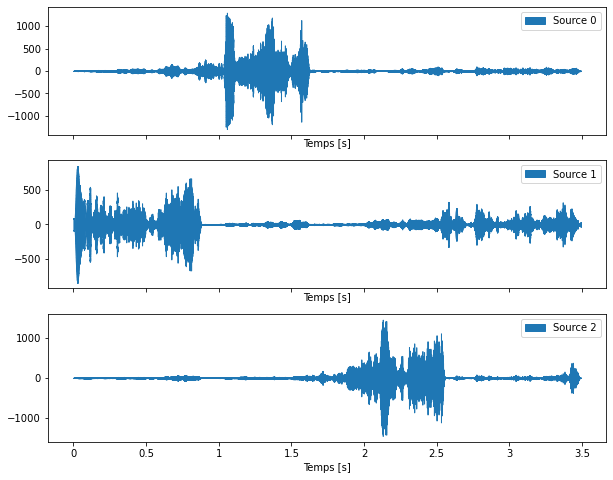

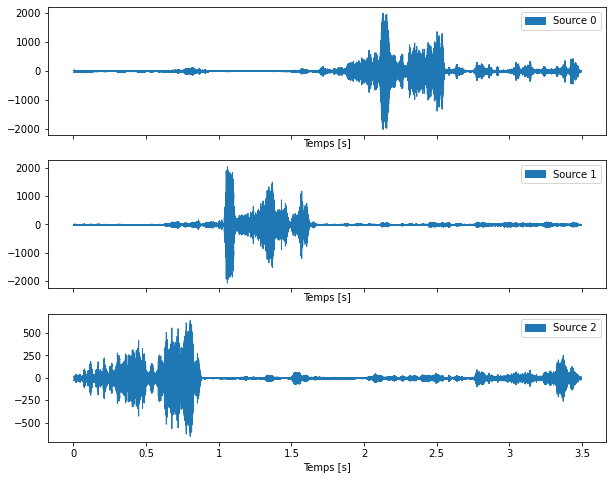

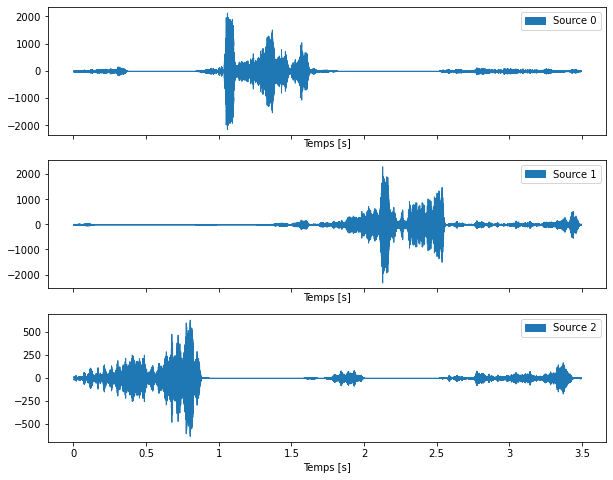

In [155]:
separation_source("piano_mix.wav",3,0)
separation_source("piano_mix.wav",3,1)
separation_source("piano_mix.wav",3,2)

On est arrivés à 5000 itérations.


'Source 0'

'Source 1'

On est arrivés à 5000 itérations.


'Source 0'

'Source 1'

On est arrivés à 5000 itérations.


'Source 0'

'Source 1'

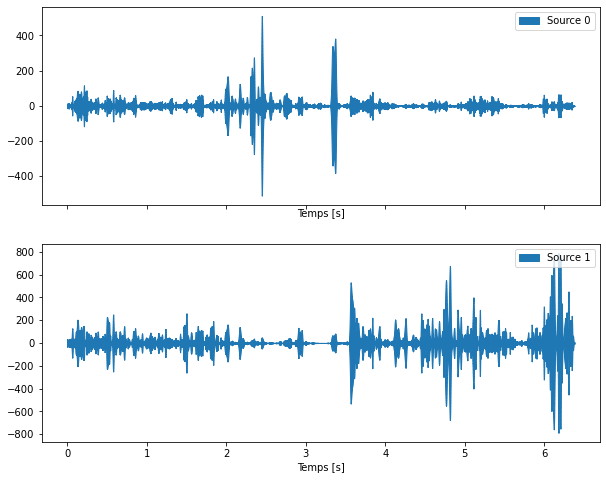

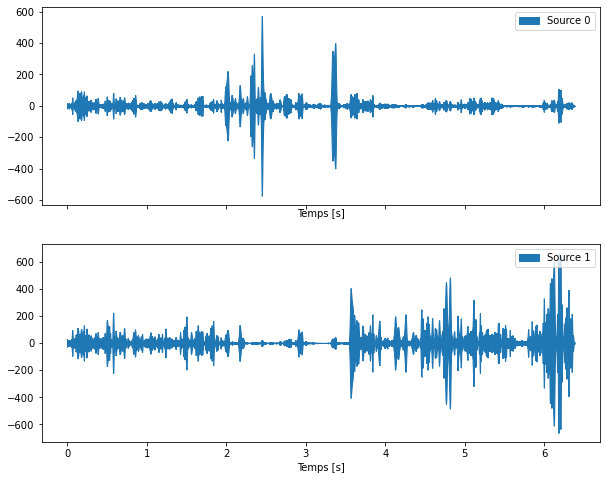

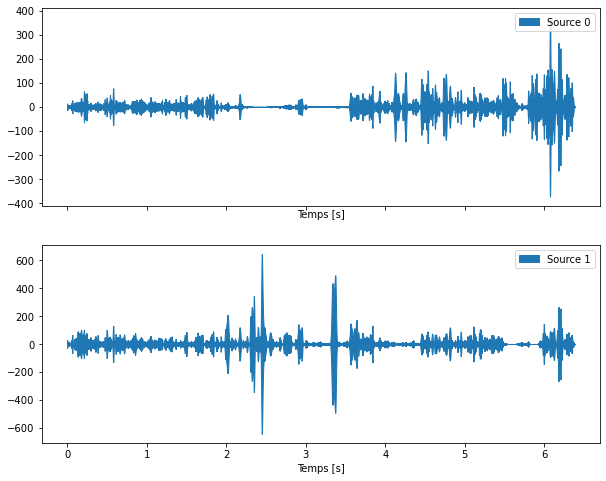

In [156]:
separation_source("horse_and_chat.wav",2,0)
separation_source("horse_and_chat.wav",2,1)
separation_source("horse_and_chat.wav",2,2)

NMF avec sklearn

(3, 76)
(257, 3)


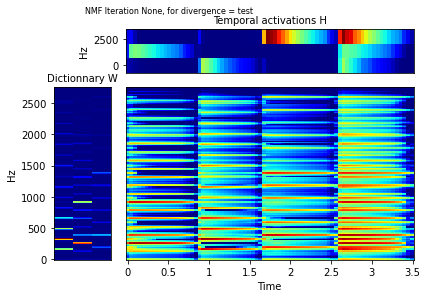

In [157]:
decomposition.NMF()
model=decomposition.NMF(n_components=3, init = 'random', random_state = 0)
son, rate = chargement_audio('piano_mix.wav')
FENETRE = 512
SAUT = 256
son_stft = librosa.stft(son, n_fft = FENETRE, hop_length = SAUT)
son_stft_Magnitude,spec=  creation_spectrogramme(son_stft)
V=init_NMF(son_stft_Magnitude)
W_sklearn = model.fit_transform(V)
H_sklearn = model.components_
plot_NMF_iter(W_sklearn,H_sklearn,'test')
#print(W_sklearn)
print(H_sklearn.shape)
print(W_sklearn.shape)

In [164]:
f, axs = plt.subplots(nrows=1, ncols=S,figsize=(20,5))
spectrogrammes_filtre = []
for i in range(S):
    axs[i].set_title(f"Frequency Mask of Audio Source s = {i+1}") 
    # Filtrage de chaque source
    WsHs = W_sklearn[:,[i]]@H_sklearn[[i],:]
    spectrogramme_filtre = W_sklearn[:,[i]]@H_sklearn[[i],:] /((W_sklearn@H_sklearn) * V +10e-10)
    # Calculer le spectrogramme filtré
    D = librosa.amplitude_to_db(spectrogramme_filtre, ref = np.max)
    # Affichage du spectrogramme filtré
    librosa.display.specshow(D,y_axis = 'hz', sr=rate,hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet, ax = axs[i])
    
    spectrogrammes_filtre.append(spectrogramme_filtre)

NameError: name 'S' is not defined

In [162]:
son_stft_angle = np.angle(son_stft)
sons_reconstruits = []
for i in range(S):
    fourier_inverse = spectrogrammes_filtre[i] * np.exp(1j*son_stft_angle)
    source_reconstruite   = librosa.istft(fourier_inverse, n_fft = FENETRE, hop_length = SAUT)
    sons_reconstruits.append(source_reconstruite)

NameError: name 'S' is not defined

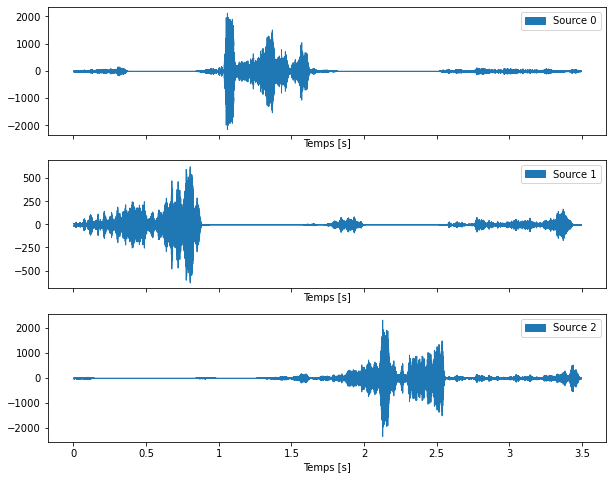

In [ ]:
fig, ax = plt.subplots(nrows=S, ncols=1, sharex=True, figsize=(10, 8))
for i in range(S):
    librosa.display.waveshow(sons_reconstruits[i], sr=rate, ax=ax[i],label=f'Source {i}',axis='time')
    ax[i].set(xlabel='Temps [s]')
    ax[i].legend()

In [ ]:
for i in range(S):
    ipd.display(f"Source {i}",ipd.Audio(sons_reconstruits[i], rate=rate))

'Source 0'

'Source 1'

'Source 2'